# Dynamic Regression

Ordinary regression can leave serial dependence in the residuals. This notebook compares OLS with a regression whose errors follow an AR(1) process, in the notation of the note on [regression with ARMA errors](../../notes/time_series/regression_with_arma_errors.md):

$$
y_t=\beta_0+\beta_1x_t+n_t,\qquad n_t=\phi n_{t-1}+\varepsilon_t.
$$

We simulate data with $\beta_0=2$, $\beta_1=1.5$, $\phi=0.8$ and compare estimates, standard errors, residual diagnostics, and forecasts.

## 1. Simulate and fit

OLS is consistent here because $x_t$ is exogenous, but its standard errors assume independent errors. The SARIMAX model estimates the regression coefficients and the AR(1) error process jointly by maximum likelihood.

In [1]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.statespace.sarimax import SARIMAX

rng = np.random.default_rng(7)
n = 250
x = rng.normal(size=n)
error = np.zeros(n)
for t in range(1, n):
    error[t] = 0.8 * error[t - 1] + rng.normal(scale=0.7)
y = 2 + 1.5 * x + error

X = sm.add_constant(x)
ols = sm.OLS(y, X).fit()
dynamic = SARIMAX(y, exog=X, order=(1, 0, 0), trend='n').fit(disp=False)

print('OLS     params:', ols.params.round(3), ' s.e.:', ols.bse.round(3))
print('Dynamic params:', dynamic.params[:2].round(3), ' s.e.:', dynamic.bse[:2].round(3))
print('Estimated AR coefficient:', dynamic.params[2].round(3), '(true 0.8)')

OLS     params: [1.697 1.6  ]  s.e.: [0.064 0.069]
Dynamic params: [1.676 1.481]  s.e.: [0.162 0.037]
Estimated AR coefficient: 0.732 (true 0.8)


Both slope estimates are near $1.5$. The dynamic model also recovers $\phi\approx0.8$, which OLS ignores. Compare standard errors: OLS assumes independent errors, so its standard errors and any forecast intervals do not reflect the serial dependence.

Ljung-Box p-values (lag 10): {'OLS': 2.845036562513836e-70, 'dynamic': 0.8630082206031149}
Durbin-Watson OLS: 0.56


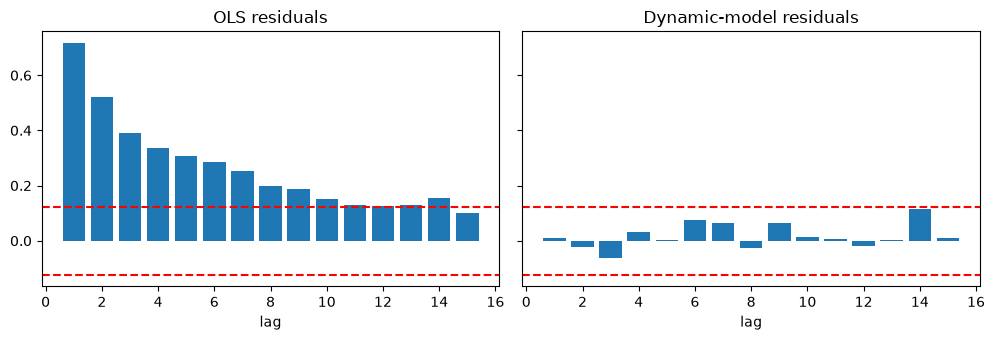

In [2]:
ols_p = acorr_ljungbox(ols.resid, lags=[10], return_df=True)['lb_pvalue'].iloc[0]
dyn_p = acorr_ljungbox(dynamic.resid, lags=[10], return_df=True)['lb_pvalue'].iloc[0]
print('Ljung-Box p-values (lag 10):', {'OLS': float(ols_p), 'dynamic': float(dyn_p)})
print('Durbin-Watson OLS:', round(durbin_watson(ols.resid), 2))

def acf_vals(r, k=15):
    r = r - r.mean()
    return np.array([np.sum(r[h:] * r[:len(r) - h]) / np.sum(r * r) for h in range(1, k + 1)])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, r, name in zip(ax, [ols.resid, dynamic.resid], ['OLS residuals', 'Dynamic-model residuals']):
    a.bar(range(1, 16), acf_vals(np.asarray(r)))
    a.axhline(1.96 / np.sqrt(n), color='r', ls='--'); a.axhline(-1.96 / np.sqrt(n), color='r', ls='--')
    a.set_title(name); a.set_xlabel('lag')
plt.tight_layout(); plt.show()

OLS residuals have a very small Ljung-Box $p$-value and a slowly decaying ACF; the dynamic model's residuals look like white noise. The error model has absorbed the serial dependence.

## 2. Forecasting uses the error process

For a one-step forecast, regression with AR(1) errors predicts $\hat y_{t+1}=\hat\beta_0+\hat\beta_1x_{t+1}+\hat\phi\,\hat n_t$. OLS drops the last term. We hold out the last 50 points and update the dynamic model one step at a time *without* re-estimating the parameters.

One-step MAE  OLS: 1.066   AR(1) errors: 0.612


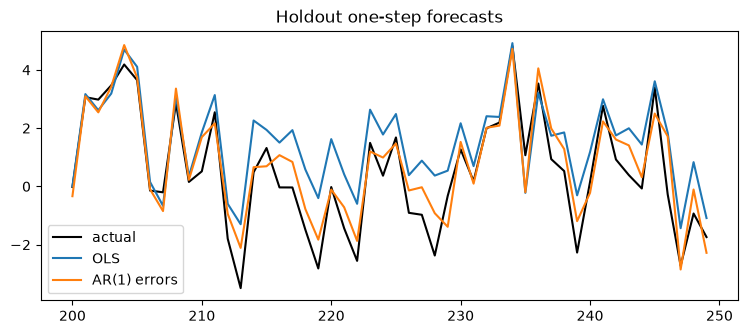

In [3]:
tr = 200
X_all = sm.add_constant(x)
ols_tr = sm.OLS(y[:tr], X_all[:tr]).fit()
f_ols = ols_tr.predict(X_all[tr:])

res = SARIMAX(y[:tr], exog=X_all[:tr], order=(1, 0, 0), trend='n').fit(disp=False)
f_dyn = []
cur = res
for i in range(tr, n):
    f_dyn.append(cur.forecast(1, exog=X_all[i:i + 1])[0])
    cur = cur.append(y[i:i + 1], exog=X_all[i:i + 1], refit=False)
f_dyn = np.array(f_dyn)

mae = lambda e: float(np.mean(np.abs(e)))
print('One-step MAE  OLS:', round(mae(y[tr:] - f_ols), 3), '  AR(1) errors:', round(mae(y[tr:] - f_dyn), 3))

plt.figure(figsize=(9, 3.5))
plt.plot(range(tr, n), y[tr:], label='actual', color='k')
plt.plot(range(tr, n), f_ols, label='OLS')
plt.plot(range(tr, n), f_dyn, label='AR(1) errors')
plt.legend(); plt.title('Holdout one-step forecasts'); plt.show()

The dynamic model has a clearly smaller one-step error because it uses the information in the last residual. Note that each forecast used the *actual* $x_{t+1}$; in practice a future predictor has to be known in advance or forecast, and that step belongs inside the backtest.

## 3. A distributed lag and collinearity

If the response depends on $x_t$ and its lags, a persistent predictor makes adjacent lag columns highly correlated, which inflates standard errors of individual weights.

In [4]:
rng = np.random.default_rng(1)
m = 400
z = np.zeros(m + 2)
for t in range(1, m + 2):
    z[t] = 0.95 * z[t - 1] + rng.normal()
x0, x1, x2 = z[2:], z[1:-1], z[:-2]
yy = 1.0 * x0 + 0.6 * x1 + 0.25 * x2 + rng.normal(scale=0.5, size=m)
fit = sm.OLS(yy, sm.add_constant(np.column_stack([x0, x1, x2]))).fit()
print('true weights   : [1.0, 0.6, 0.25]')
print('estimated      :', fit.params[1:].round(3))
print('std errors     :', fit.bse[1:].round(3))
print('corr(x_t, x_t-1) =', round(np.corrcoef(x0, x1)[0, 1], 2))
print('sum of weights  :', round(fit.params[1:].sum(), 3), '(true 1.85)')

true weights   : [1.0, 0.6, 0.25]
estimated      : [1.048 0.609 0.185]
std errors     : [0.029 0.037 0.029]
corr(x_t, x_t-1) = 0.91
sum of weights  : 1.842 (true 1.85)


Individual weights are estimated with visible uncertainty, but the long-run multiplier (their sum) is well determined. Dynamic regression should be described by the full equation, the lag convention, the error model, and a forecast procedure that uses only information available at the forecast origin.